# ST10355869

Intel Image dataset

# Setup

In [1]:
#install the needed imports
%pip install pyspark tensorflow pandas matplotlib seaborn scikit-learn Pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from pyspark.sql import SparkSession  


#import tensflow packages for model training
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import load_model

from pyspark.sql.functions import col, split, element_at, input_file_name, regexp_extract
from pyspark.sql import functions as F



import matplotlib.pyplot as plt
#initialise spark session


spark = (
    SparkSession.builder
    .appName("PDAN8412_P3")
    .config("spark.memory.offHeap.enabled", "true")
    .config("spark.memory.offHeap.size", "10g")
    .getOrCreate()
)

In [3]:
base = "file:///C:/varsity/PostGrad/Semester 2/PDAN8412/Part 3/Part 3 code/part 3 dataset"

#get the dimenions of the images in the training data
image_df_train = (
    spark.read.format("image")
    .option("recursiveFileLookup", "true")
      #drop invalid images that may be corrupted, these are null values
    .option("dropInvalid", True)
    .load(f"{base}\\seg_train")
    .select(
        "image",
        "image.origin",
        "image.height",
        "image.width",
        "image.nChannels",
        "image.mode"
    )
    .withColumn("label", element_at(split(col("origin"), r"[/\\]"), -2))
)
#get the relevant data for the test data
image_df_test = (
    spark.read.format("image")
    .option("recursiveFileLookup", "true")
    .option("dropInvalid", True)
    .load(f"{base}\\seg_test")
    .select(
        "image",
        "image.origin",
        "image.height",
        "image.width",
        "image.nChannels",
        "image.mode"
    )
    .withColumn("label", element_at(split(col("origin"), r"[/\\]"), -2))
)
#check that the data has been loaded to dataframesw
image_df_train.printSchema()
image_df_test.printSchema()

root
 |-- image: struct (nullable = true)
 |    |-- origin: string (nullable = true)
 |    |-- height: integer (nullable = true)
 |    |-- width: integer (nullable = true)
 |    |-- nChannels: integer (nullable = true)
 |    |-- mode: integer (nullable = true)
 |    |-- data: binary (nullable = true)
 |-- origin: string (nullable = true)
 |-- height: integer (nullable = true)
 |-- width: integer (nullable = true)
 |-- nChannels: integer (nullable = true)
 |-- mode: integer (nullable = true)
 |-- label: string (nullable = true)

root
 |-- image: struct (nullable = true)
 |    |-- origin: string (nullable = true)
 |    |-- height: integer (nullable = true)
 |    |-- width: integer (nullable = true)
 |    |-- nChannels: integer (nullable = true)
 |    |-- mode: integer (nullable = true)
 |    |-- data: binary (nullable = true)
 |-- origin: string (nullable = true)
 |-- height: integer (nullable = true)
 |-- width: integer (nullable = true)
 |-- nChannels: integer (nullable = true)
 |-- mo

# EDA

In [4]:
image_df_train.groupBy("label").count().orderBy("label").show()



+---------+-----+
|    label|count|
+---------+-----+
|buildings| 2191|
|   forest| 2271|
|  glacier| 2404|
| mountain| 2512|
|      sea| 2274|
|   street| 2382|
+---------+-----+



the classes have a relative balance between all classes where they are around 2200-2400

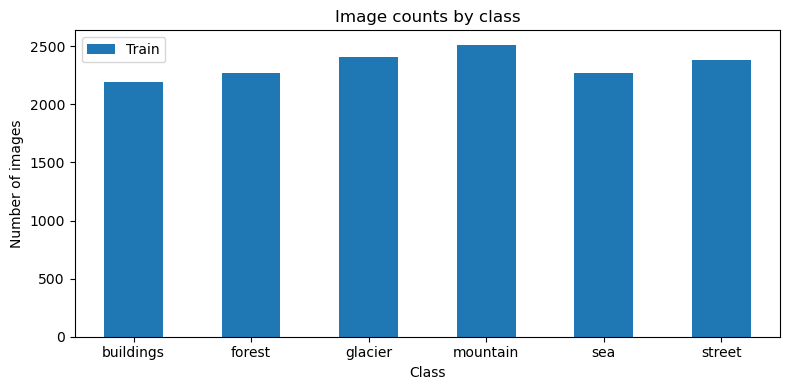

In [5]:

#create a count in spark and convert to pandas for plotting
train_counts = (
    image_df_train.groupBy("label").count()
    .withColumnRenamed("count", "Train")
    .orderBy("label")
    .toPandas()
    .set_index("label")
)
ax = train_counts.plot(kind="bar", figsize=(8, 4))
ax.set_title("Image counts by class")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=0)


plt.tight_layout()
plt.show()

all relatively the same, there are more mountain images in total and the least is buildings but there is no big imbalance between classes that require a need for techniques to balance class weights.

## Test-train original split

the dataset is already split into a train and test set with the relevant labels so checking what the split is and if it can be used for the model or if the data should be combined.

In [6]:
#checking total amount to see the split from download
print(f"Total number of images: {image_df_train.count()}")

Total number of images: 14034


checking the test set for the quantity in it

In [7]:

image_df_test.groupBy("label").count().orderBy("label").show()
print(f"Total number of test images: {image_df_test.count()}")

+---------+-----+
|    label|count|
+---------+-----+
|buildings|  437|
|   forest|  474|
|  glacier|  553|
| mountain|  525|
|      sea|  510|
|   street|  501|
+---------+-----+

Total number of test images: 3000


In [8]:
total_images = image_df_train.count() + image_df_test.count()
print(f"Total number of images: {total_images}")

Total number of images: 17034


In [9]:
test_share = image_df_test.count()/total_images
train_share = image_df_train.count()/total_images

print(f"Share of test images: {test_share:.2%}")
print(f"Share of train images: {train_share:.2%}")

Share of test images: 17.61%
Share of train images: 82.39%


sufficient split to use the original split, just over a 80/20 split with enough test entries in the test dataset. keeping it seperate will also allow for no data leakage to happen

## Samples

Viewing 3 samples for each class can identify what differences there are between images and how they are displayed

In [10]:
import random
from PIL import Image
import matplotlib.pyplot as plt

def show_class_samples(meta_df, n_per_class=3, seed=42):
    classes = sorted(meta_df["label"].unique())
    fig, axes = plt.subplots(len(classes), n_per_class,
                             figsize=(12, 3 * len(classes)), squeeze=False)
    rng = random.Random(seed)

    for i, cls in enumerate(classes):
        paths = meta_df.loc[meta_df["label"] == cls, "path"].tolist()
        picks = rng.sample(paths, min(n_per_class, len(paths)))
        for j, p in enumerate(picks):
            ax = axes[i, j]
            ax.imshow(Image.open(p))
            ax.axis("off")
            if j == 0:
                ax.set_title(cls, fontsize=11, loc="left", fontweight="bold")

    plt.tight_layout()
    plt.show()



## Resolution

CNN need consistent resolution for the input data so a check needs to be done to see what resolution these images are

In [11]:
#check the heigh and width of the images in the dataset
image_df_train.groupBy("height", "width").count().orderBy(F.desc("count")).show(5)


+------+-----+-----+
|height|width|count|
+------+-----+-----+
|   150|  150|13986|
|   113|  150|    7|
|   135|  150|    3|
|   111|  150|    3|
|   108|  150|    2|
+------+-----+-----+
only showing top 5 rows


the majority of the dimensions are 150x150, to see the exact number of changes the dataset will be filtered to see before and after

In [12]:
#create a copy of image dataframe to use for exploring
df = image_df_train

In [13]:
before_filter = image_df_train.count()
image_df_train = image_df_train.filter((col("height") == 150) & (col("width") == 150))
print(f"Number of images before filtering: {before_filter}")
print(f"Number of images after filtering: {image_df_train.count()}")

Number of images before filtering: 14034
Number of images after filtering: 13986


In [14]:
print(f"Number of images filtered out: {before_filter - image_df_train.count()}")

Number of images filtered out: 48


48 images were removed from the filter, to keep the size of the dataset these will still be kept since they will be able to be fit to the dimensions before training in tensorflow, this allows for the model to have as much data as possible even if it is only a small amount that would be left out of

In [15]:
#assign the before filtered datafrae to original dataframe
image_df_train = df

## Duplicates

to check for duplicates in images, they can be hashed and the numbers compared to see duplicates

In [16]:

df_hashed = image_df_train.withColumn("image_hash", F.sha2("image.data", 256))

# Group to see which hashes appear more than once
duplicate_hashes = (
    df_hashed.groupBy("image_hash")
    .agg(
        F.count("*").alias("count"),
        F.collect_list("image.origin").alias("duplicate_paths"),
    )
    .filter(F.col("count") > 1)
)
#number of duplicate images
num_duplicates = duplicate_hashes.count()
print(f"Number of duplicate images: {num_duplicates}")



Number of duplicate images: 15


duplicates will be dropped

In [17]:
#count number of images before and after dropping duplicates to make sure the duplicates are dropped
before_drop_duplicates = image_df_train.count()
image_df_train = df_hashed.dropDuplicates(["image_hash"])
after_drop_duplicates = image_df_train.count()
print(f"Number of images before dropping duplicates: {before_drop_duplicates}")
print(f"Number of images after dropping duplicates: {after_drop_duplicates}")

Number of images before dropping duplicates: 14034
Number of images after dropping duplicates: 14019


### split duplicates

These are duplicate in the training set, since the test set is already split, a check for duplicates between the 2 sets will be needed so that there are not copies of the same image.

In [18]:
train_hashes = df_hashed.select("image_hash").distinct()
#hash test images using same hashing type
test_hashed = image_df_test.withColumn("image_hash", F.sha2("image.data", 256))

leaked = (
    test_hashed
    .join(F.broadcast(train_hashes), on="image_hash", how="inner")
)

print(f"Test images that also appear in train: {leaked.count()}")
leaked.select("origin", "label", "image_hash").show(truncate=False)

Test images that also appear in train: 3
+--------------------------------------------------------------------------------------------------------------------------+---------+----------------------------------------------------------------+
|origin                                                                                                                    |label    |image_hash                                                      |
+--------------------------------------------------------------------------------------------------------------------------+---------+----------------------------------------------------------------+
|file:///C:/varsity/PostGrad/Semester%202/PDAN8412/Part%203/Part%203%20code/part%203%20dataset/seg_test/glacier/21469.jpg  |glacier  |3aee9b36fe888fce2f536faff91df84a51d02c4edf92d85e220e151c60313304|
|file:///C:/varsity/PostGrad/Semester%202/PDAN8412/Part%203/Part%203%20code/part%203%20dataset/seg_test/buildings/20805.jpg|buildings|07e348fc4393b15a4dc1b76ed

since there are duplicates between the sets, i will remove them from the test set so that the model can still train on them

In [19]:
#drop from the test set
image_df_test = (
    test_hashed
    .join(F.broadcast(train_hashes), on="image_hash", how="left_anti")
    .drop("image_hash")
)

#check the  number of images and see if they are removed
image_df_test.groupBy("label").count().orderBy("label").show()
print(f"Total number of test images: {image_df_test.count()}")

+---------+-----+
|    label|count|
+---------+-----+
|buildings|  436|
|   forest|  474|
|  glacier|  552|
| mountain|  525|
|      sea|  510|
|   street|  500|
+---------+-----+

Total number of test images: 2997


the 3 images were dropped, looking at the label count there was 1 duplicate in buildings, 1 in glacier and 1 in the street class

# Tensor Setup

To allow the use of tensorflos packages in preparing the dataset, a copy of the cleaned dataframe will be created. this allows for the processing to be done in tensor and helps when preparing the data for the model.

In [20]:
#convert to pandas
train_meta = image_df_train.select("origin", "label").toPandas()
test_meta  = image_df_test.select("origin", "label").toPandas()

# Consistent class order for train AND test
classes = sorted(train_meta["label"].unique())         
class_to_idx = {c: i for i, c in enumerate(classes)}

train_meta["y"] = train_meta["label"].map(class_to_idx).astype("int32")
test_meta["y"]  = test_meta["label"].map(class_to_idx).astype("int32")

In [21]:
from urllib.parse import urlparse, unquote

def to_local(uri: str) -> str:
    p = unquote(urlparse(uri).path)      
    return p.lstrip("/")               

train_meta["path"] = train_meta["origin"].map(to_local)
test_meta["path"]  = test_meta["origin"].map(to_local)

check that the count for the new paths are the same

In [22]:
print(len(train_meta), image_df_train.count())   
print(len(test_meta),  image_df_test.count())      
print(train_meta["label"].value_counts().sort_index())

14019 14019
2997 2997
label
buildings    2191
forest       2269
glacier      2404
mountain     2506
sea          2272
street       2377
Name: count, dtype: int64


# CNN Model

This section in the notebook is setting up the data to be used in a model and also setting up the model hyperparamaters.

## data preparation

the training data will be split into training and validation data

In [23]:
from sklearn.model_selection import train_test_split
training, validation = train_test_split(train_meta, test_size=0.2, stratify=train_meta["y"], random_state=42)

split data before anything is done so that only the changes will be done to the training split to avoid data leakage.

## preprocess

need to preprocess the data so it is consistent and allows cnn to learn correctly

In [24]:
#setup a pipeline to process the training data
IMG_SIZE=(150,150)
def process_image(path,label):
    # Read the image from the file
    image = tf.io.read_file(path)
    # decode the image
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

#create a dataset table that can be used in tensor model
def make_ds(meta, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((meta["path"].values, meta["y"].values))
    if shuffle:
        ds = ds.shuffle(len(meta), seed=42)
    return ds.map(process_image, num_parallel_calls=tf.data.AUTOTUNE).batch(32).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(training, shuffle=True)
val_ds = make_ds(validation)
test_ds = make_ds(test_meta)

the above code is where the path of the image in the folder and then the label that relates to each class

## sample images

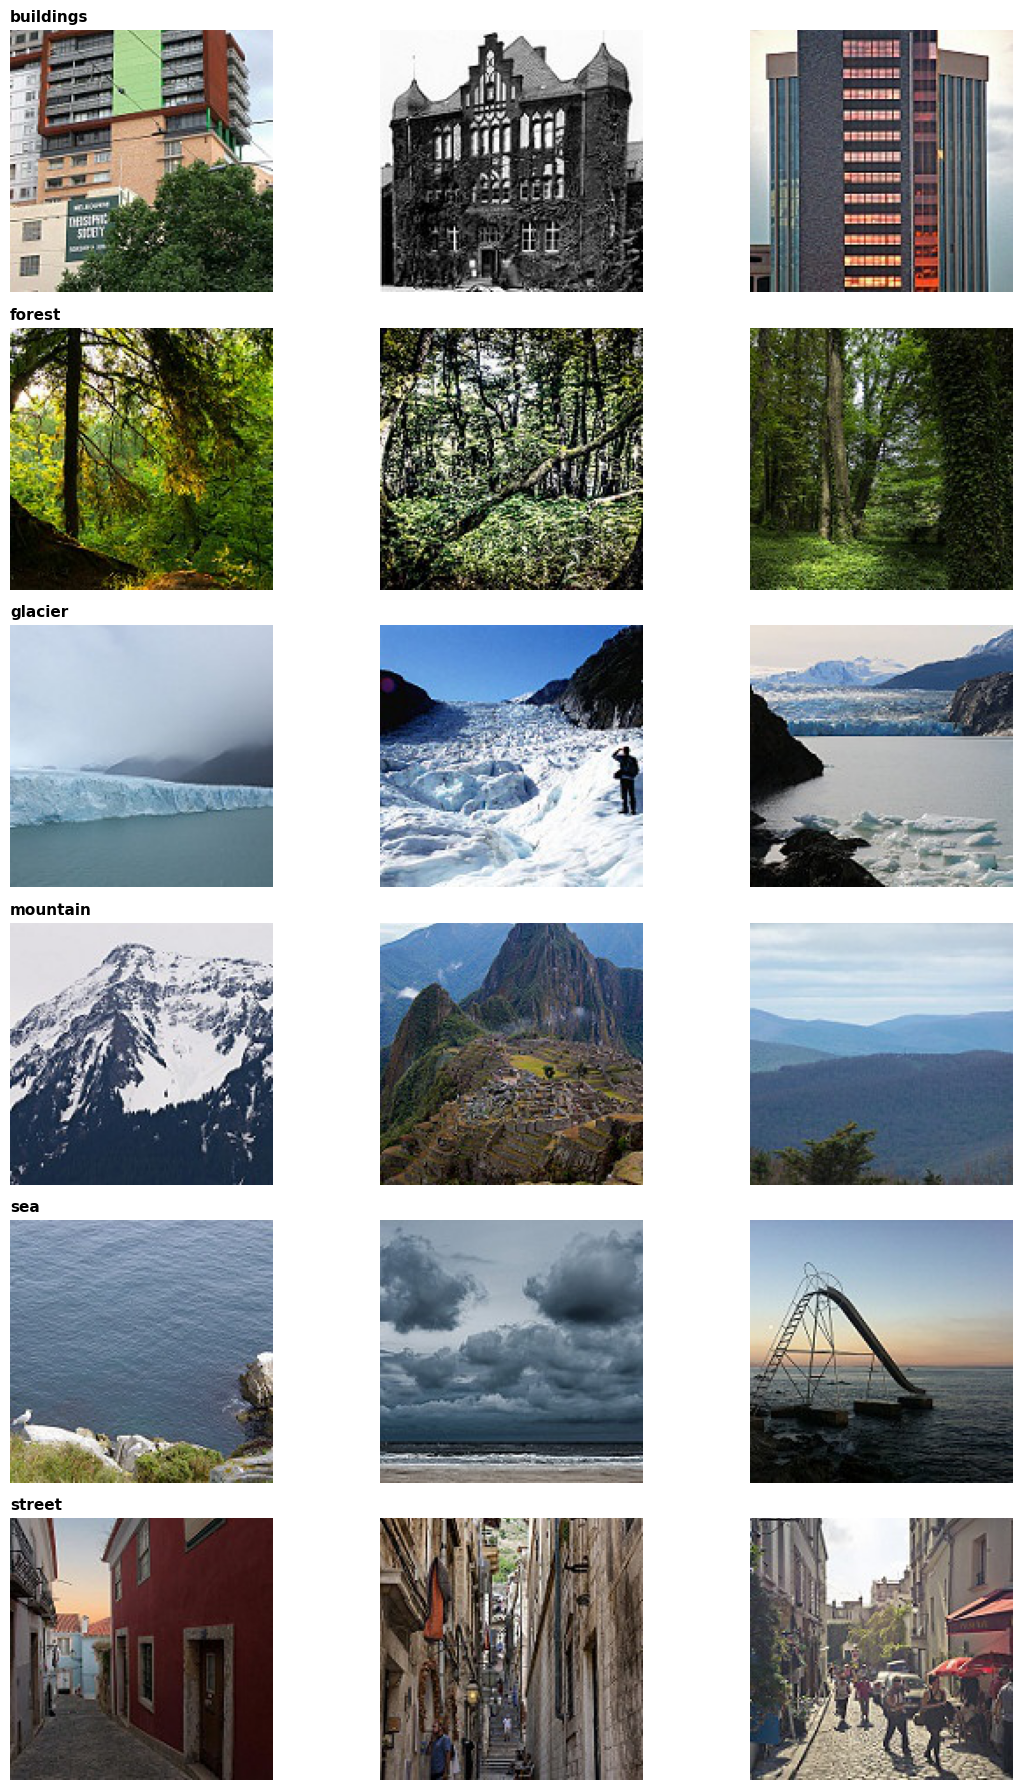

In [25]:
show_class_samples(train_meta, n_per_class=3)

# Models

## Base Model

### layer setup


to enhance the learning capabilities the image data can be augmented to help in creating more training images, this is done by creating copies of the images and changing the angle of the image by flipping it or rotating.

In [28]:
from tensorflow.keras import layers, Sequential
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    layers.Input(shape=(150, 150, 3)),     
    #augment the data to help reduce overfitting
    layers.Rescaling(1./255),  
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1), 
    layers.RandomZoom(0.1),              
    #convolutional layers
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    #output layer with 6 nodes for each class
    layers.Dense(6, activation="softmax"),
])

### Fit to data

fit the data to the model and create an early stop incase validation loss increases 3 times, this allows for the model to stop before the validation loss gets bigger

In [29]:
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

model.compile(
    optimizer="adam",                    
    loss="sparse_categorical_crossentropy",  
    metrics=["accuracy"],
)

history = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=[early_stop])

Epoch 1/20


351/351 ━━━━━━━━━━━━━━━━━━━━ 71s 199ms/step - accuracy: 0.5878 - loss: 1.0968 - val_accuracy: 0.6737 - val_loss: 0.9157
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 61s 174ms/step - accuracy: 0.6741 - loss: 0.8804 - val_accuracy: 0.7051 - val_loss: 0.9164
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 62s 176ms/step - accuracy: 0.7079 - loss: 0.8005 - val_accuracy: 0.7475 - val_loss: 0.7398
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 61s 174ms/step - accuracy: 0.7258 - loss: 0.7503 - val_accuracy: 0.7486 - val_loss: 0.7321
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 62s 175ms/step - accuracy: 0.7502 - loss: 0.7026 - val_accuracy: 0.7660 - val_loss: 0.6975
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 62s 178ms/step - accuracy: 0.7619 - loss: 0.6784 - val_accuracy: 0.7575 - val_loss: 0.7715
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 61s 173ms/step - accuracy: 0.7679 - loss: 0.6549 - val_accuracy: 0.7521 - val_loss: 0.7709
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 61s 173ms/step - accuracy: 0.7717 - loss: 0.6412 - val

### Evaluation

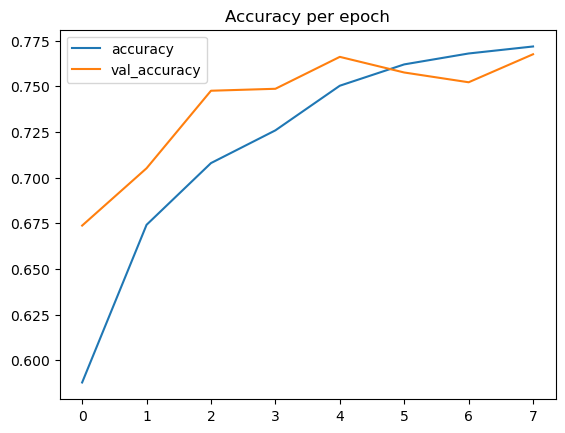

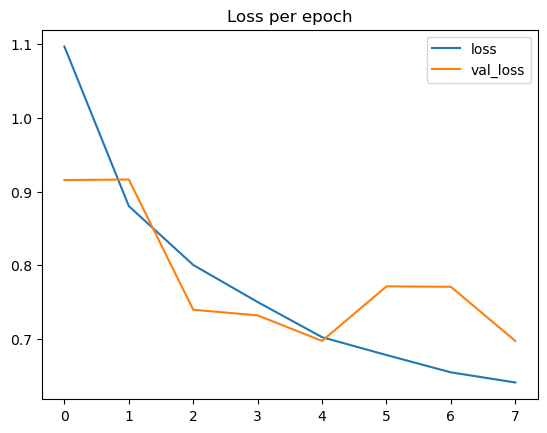

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.7651 - loss: 0.6872
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step
Test accuracy: 0.7651
              precision    recall  f1-score   support

   buildings       0.66      0.77      0.71       436
      forest       0.94      0.93      0.93       474
     glacier       0.78      0.64      0.70       552
    mountain       0.66      0.79      0.72       525
         sea       0.85      0.61      0.71       510
      street       0.77      0.86      0.82       500

    accuracy                           0.77      2997
   macro avg       0.78      0.77      0.77      2997
weighted avg       0.78      0.77      0.76      2997



In [30]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report

hist = pd.DataFrame(history.history)
hist[["accuracy", "val_accuracy"]].plot(title="Accuracy per epoch")
hist[["loss", "val_loss"]].plot(title="Loss per epoch")
plt.show()

test_loss, test_acc = model.evaluate(test_ds)
y_pred = np.argmax(model.predict(test_ds), axis=1)
y_true = test_meta["y"].values
print(f"Test accuracy: {test_acc:.4f}")
print(classification_report(y_true, y_pred, target_names=classes))


## Improved model

### Dropout 

to improve the model regularisation will be used to check if that can help with the overfitting

In [31]:
#only adding dropout to see what the change will do
model_reg = Sequential([
    layers.Input(shape=(150, 150, 3)),   
    #same augmentation
    layers.Rescaling(1./255),  
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1), 
    layers.RandomZoom(0.1),  
    #convolutional layers  
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    #adding dropout layer 
    layers.Dropout(0.5),
    layers.Dense(6, activation="softmax"),
])
 

Compile new model

In [32]:
model_reg.compile(
    optimizer="adam",                    
    loss="sparse_categorical_crossentropy",  
    metrics=["accuracy"],
)
#Use the same early stopping
history_reg = model_reg.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=[early_stop])

Epoch 1/20


c:\Users\kevin\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 64s 180ms/step - accuracy: 0.5817 - loss: 1.1011 - val_accuracy: 0.6715 - val_loss: 0.8796
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 65s 185ms/step - accuracy: 0.6585 - loss: 0.9105 - val_accuracy: 0.6558 - val_loss: 1.0369
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 62s 177ms/step - accuracy: 0.6966 - loss: 0.8363 - val_accuracy: 0.7290 - val_loss: 0.7948
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 63s 179ms/step - accuracy: 0.7169 - loss: 0.7795 - val_accuracy: 0.7154 - val_loss: 0.7992
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 63s 181ms/step - accuracy: 0.7318 - loss: 0.7433 - val_accuracy: 0.7596 - val_loss: 0.6892
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 64s 182ms/step - accuracy: 0.7396 - loss: 0.7149 - val_accuracy: 0.7814 - val_loss: 0.6406
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 63s 181ms/step - accuracy: 0.7535 - loss: 0.6825 - val_accuracy: 0.7514 - val_loss: 0.7599
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 63s 180ms/step - accuracy: 0.7598 - loss: 0.6579 - val

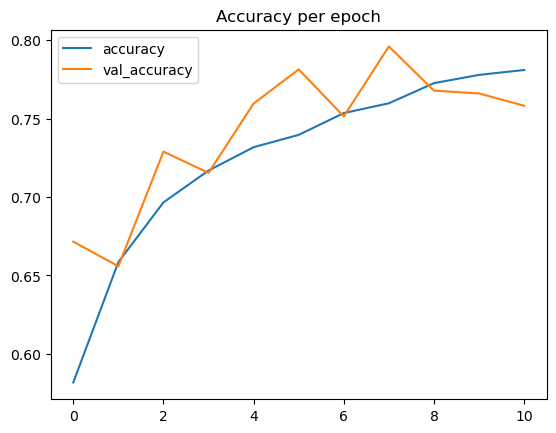

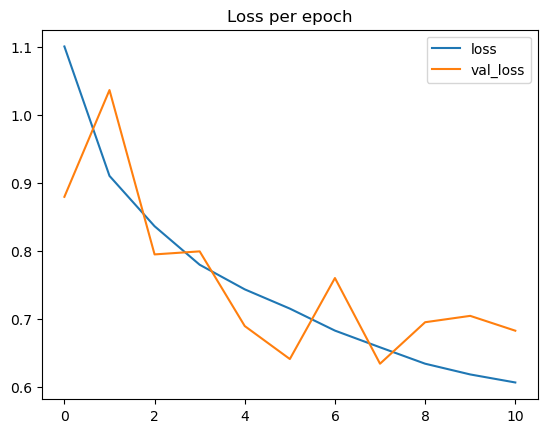

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.7975 - loss: 0.6025
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step
Test accuracy: 0.7975
              precision    recall  f1-score   support

   buildings       0.72      0.83      0.77       436
      forest       0.92      0.94      0.93       474
     glacier       0.78      0.76      0.77       552
    mountain       0.74      0.76      0.75       525
         sea       0.83      0.71      0.76       510
      street       0.81      0.82      0.81       500

    accuracy                           0.80      2997
   macro avg       0.80      0.80      0.80      2997
weighted avg       0.80      0.80      0.80      2997



In [33]:
hist_reg = pd.DataFrame(history_reg.history)
hist_reg[["accuracy", "val_accuracy"]].plot(title="Accuracy per epoch")
hist_reg[["loss", "val_loss"]].plot(title="Loss per epoch")
plt.show()

test_loss, test_acc = model_reg.evaluate(test_ds)
y_pred_reg = np.argmax(model_reg.predict(test_ds), axis=1)
y_true_reg = test_meta["y"].values
print(f"Test accuracy: {test_acc:.4f}")
print(classification_report(y_true_reg, y_pred_reg, target_names=classes))

### Adding layers

In [34]:
model_layer = Sequential([
   layers.Input(shape=(150, 150, 3)),   
     #same augmentation
    layers.Rescaling(1./255),  
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1), 
    layers.RandomZoom(0.1),  
    #convolutional layers  
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    #adding dropout layer 
    layers.Dropout(0.5),
    layers.Dense(6, activation="softmax"),
])

In [36]:
#create new early stopping to see if training for longer will improve accuracy
early_stop_new = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

model_layer.compile(
    optimizer="adam",                    
    loss="sparse_categorical_crossentropy",  
    metrics=["accuracy"],
)
#3 epochs since that is where there is the start of an increase in validation loss, indicating overfitting.
history_layers = model_layer.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=[early_stop_new])

Epoch 1/20


c:\Users\kevin\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 81s 228ms/step - accuracy: 0.6818 - loss: 0.8640 - val_accuracy: 0.7029 - val_loss: 0.8174
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 80s 229ms/step - accuracy: 0.7156 - loss: 0.7668 - val_accuracy: 0.7297 - val_loss: 0.7488
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 80s 229ms/step - accuracy: 0.7471 - loss: 0.6967 - val_accuracy: 0.7011 - val_loss: 0.8019
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 78s 223ms/step - accuracy: 0.7587 - loss: 0.6677 - val_accuracy: 0.7418 - val_loss: 0.7305
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 79s 224ms/step - accuracy: 0.7742 - loss: 0.6209 - val_accuracy: 0.7860 - val_loss: 0.6362
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 80s 227ms/step - accuracy: 0.7827 - loss: 0.5973 - val_accuracy: 0.7671 - val_loss: 0.6727
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 81s 231ms/step - accuracy: 0.7919 - loss: 0.5806 - val_accuracy: 0.7785 - val_loss: 0.6622
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 78s 223ms/step - accuracy: 0.7926 - loss: 0.5682 - val

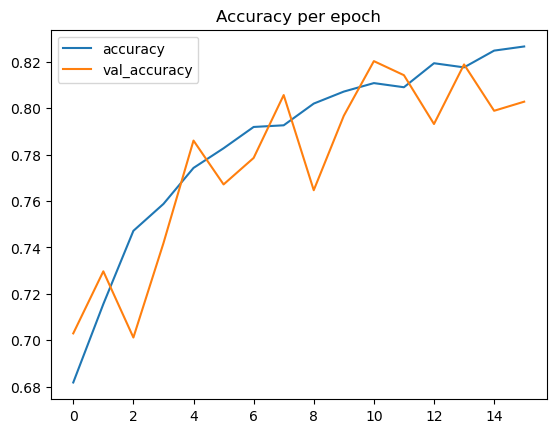

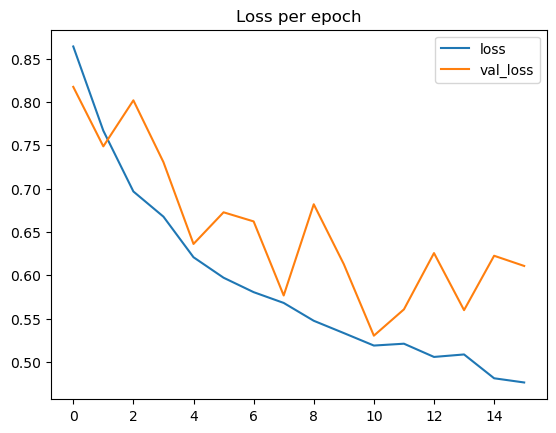

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.8228 - loss: 0.5129
94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step
Test accuracy: 0.8228
              precision    recall  f1-score   support

   buildings       0.88      0.70      0.78       436
      forest       0.95      0.97      0.96       474
     glacier       0.82      0.76      0.79       552
    mountain       0.78      0.75      0.77       525
         sea       0.77      0.84      0.80       510
      street       0.77      0.92      0.84       500

    accuracy                           0.82      2997
   macro avg       0.83      0.82      0.82      2997
weighted avg       0.83      0.82      0.82      2997



In [ ]:
hist_layer = pd.DataFrame(history_layers.history)
hist_layer[["accuracy", "val_accuracy"]].plot(title="Accuracy per epoch")
hist_layer[["loss", "val_loss"]].plot(title="Loss per epoch")
plt.show()
#get the accuracy and loss of model during training
test_loss, test_acc = model_layer.evaluate(test_ds)
y_pred_layer = np.argmax(model_layer.predict(test_ds), axis=1)
y_true_layer = test_meta["y"].values

print(f"Test accuracy: {test_acc:.4f}")
print(classification_report(y_true_layer, y_pred_layer, target_names=classes))

# save models for final evaluation

In [ ]:
import os


#save the models that will be used in the report
model.save("baseline_cnn.keras")
model_reg.save("dropout_cnn.keras")
model_layer.save("moreLayers_cnn.keras")

In [39]:
#load these models
model_baseline  = tf.keras.models.load_model("baseline_cnn.keras")
model_dropout   = tf.keras.models.load_model("dropout_cnn.keras")
model_moreLayers = tf.keras.models.load_model("moreLayers_cnn.keras")

get the classification report for these models that will be used in the report

In [41]:
from tensorflow.keras.models import load_model
y_true = test_meta["y"].values

baseline_model = load_model("baseline_cnn.keras")
test_loss, test_acc = baseline_model.evaluate(test_ds)
y_pred_baseline = np.argmax(baseline_model.predict(test_ds), axis=1)

print(f"Test accuracy: {test_acc:.4f}")
print(classification_report(y_true, y_pred_baseline, target_names=classes))

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.7651 - loss: 0.6872
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step
Test accuracy: 0.7651
              precision    recall  f1-score   support

   buildings       0.66      0.77      0.71       436
      forest       0.94      0.93      0.93       474
     glacier       0.78      0.64      0.70       552
    mountain       0.66      0.79      0.72       525
         sea       0.85      0.61      0.71       510
      street       0.77      0.86      0.82       500

    accuracy                           0.77      2997
   macro avg       0.78      0.77      0.77      2997
weighted avg       0.78      0.77      0.76      2997



In [42]:
dropout_model = load_model("dropout_cnn.keras")
test_loss, test_acc = dropout_model.evaluate(test_ds)
y_pred_dropout = np.argmax(dropout_model.predict(test_ds), axis=1)

print(f"Test accuracy: {test_acc:.4f}")
print(classification_report(y_true, y_pred_dropout, target_names=classes))

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.7975 - loss: 0.6025
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step
Test accuracy: 0.7975
              precision    recall  f1-score   support

   buildings       0.72      0.83      0.77       436
      forest       0.92      0.94      0.93       474
     glacier       0.78      0.76      0.77       552
    mountain       0.74      0.76      0.75       525
         sea       0.83      0.71      0.76       510
      street       0.81      0.82      0.81       500

    accuracy                           0.80      2997
   macro avg       0.80      0.80      0.80      2997
weighted avg       0.80      0.80      0.80      2997



In [43]:
more_layers_model = load_model("moreLayers_cnn.keras")
test_loss, test_acc = more_layers_model.evaluate(test_ds)
y_pred_more = np.argmax(more_layers_model.predict(test_ds), axis=1)

print(f"Test accuracy: {test_acc:.4f}")
print(classification_report(y_true, y_pred_more, target_names=classes))

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.8228 - loss: 0.5129
94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step
Test accuracy: 0.8228
              precision    recall  f1-score   support

   buildings       0.88      0.70      0.78       436
      forest       0.95      0.97      0.96       474
     glacier       0.82      0.76      0.79       552
    mountain       0.78      0.75      0.77       525
         sea       0.77      0.84      0.80       510
      street       0.77      0.92      0.84       500

    accuracy                           0.82      2997
   macro avg       0.83      0.82      0.82      2997
weighted avg       0.83      0.82      0.82      2997

